# Lección30: unidades, varianza y rango de máquina
## 1 Pregunta y continuidad
El29 verificó cancelación con offset y admitió que datos finitos pueden producir M2 infinito. Aquí no cambiamos algoritmo29: lo envolvemos con escala externa binaria y salida tipada. ¿Podemos recuperar una desviación estándar finita aun si su cuadrado no cabe?
## 2 Derivación propia de una identidad clásica
Sea $s=2^e>0$, $y_i=x_i/s$ y $\bar y=n^{-1}\sum y_i$. Entonces $\bar x=s\bar y$ y
$$M_{2,x}=\sum_i(x_i-\bar x)^2=s^2\sum_i(y_i-\bar y)^2=s^2M_{2,y}.$$
Para $d\in\{0,1\}$ con $n>d$,
$$V_{x,d}=2^{2e}\frac{M_{2,y}}{n-d},\qquad \sigma_{x,d}=2^e\sqrt{\frac{M_{2,y}}{n-d}}.$$
**Correspondencia código:** `scaled_moments` usa `ldexp(x,-exponent)`; el núcleo29 calcula M2; `ldexp(variance_scaled,2*exponent)` y `ldexp(sqrt(...),exponent)` devuelven unidades. Varianza tiene unidades U², SD U. No es fórmula inédita ni cota universal de error. Escala se declara, no se aprende de datos futuros.
## 3 Hipótesis local/configuración
Para seis fixtures con e=frexp(unit)[1], error relativo SD<=1e-12. unit1,1e200,1e-200, n128/4096. Decimal80 sobre floats recibidos. Dominio operacional: cada observación normalizada no nula tiene magnitud entre2^-400 y2^400; fuera devuelve normalization_failure, para ajustar e.

In [1]:
import math,json,csv
from pathlib import Path
from IPython.display import display,Image
from src.scaled import scaled_moments
x=[1e200,2e200,3e200,4e200]
a=scaled_moments(x,665)
print(a)
assert a.status=='variance_overflow' and math.isfinite(a.std)
print('SD/unidad:',a.std/1e200,'vs sqrt(1.25):',math.sqrt(1.25))

ScaleResult(n=4, exponent=665, status='variance_overflow', variance=None, std=1.1180339887498949e+200)
SD/unidad: 1.118033988749895 vs sqrt(1.25): 1.118033988749895


## 4 Experimento y sensibilidad
¿Por qué elegir potencias de dos? La operación desplaza exponente sin introducir división decimal, siempre que el resultado siga representable. La ventana2^±400 es conservadora, no óptima; evita muchas normalizaciones peligrosas pero sacrifica rango dinámico mixto. No elimina pérdida de representación anterior al ingreso. Variamos e por±400/±1000 y registramos rechazos, no los escondemos del denominador.

In [2]:
s=json.loads(Path('results/scale_summary.json').read_text())
print(json.dumps(s,indent=2))
rows=list(csv.DictReader(Path('results/scale_raw.csv').open()))
print([r for r in rows if r['n']=='128' and r['method']=='scaled'])

{
  "rows": 42,
  "chosen_cases": 6,
  "chosen_statuses": {
    "variance_underflow": 2,
    "variance_overflow": 2,
    "ok": 2
  },
  "chosen_max_relative_sd_error": 1.7763568394002505e-15,
  "baseline_failures": {
    "kernel29": 4,
    "numpy_two_pass": 4
  },
  "environment": {
    "python": "3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]",
    "platform": "Linux-6.18.57-x86_64-with-glibc2.39",
    "processor": "x86_64",
    "numpy": "2.3.5"
  },
  "timing": "5 calls median; no tracemalloc during timing; memory separate Python allocations only, not RSS; no claim of throughput improvement"
}
[{'n': '128', 'unit': '1.0', 'method': 'scaled', 'exponent': '-999', 'delta': '-1000', 'status': 'normalization_failure', 'variance': '', 'std': '', 'oracle_std': '1.118033988749895', 'relative_std_error': '', 'median_ns': '1742', 'python_peak_bytes': '576'}, {'n': '128', 'unit': '1.0', 'method': 'scaled', 'exponent': '-399', 'delta': '-400', 'status': 'normalization_failure', 'variance'

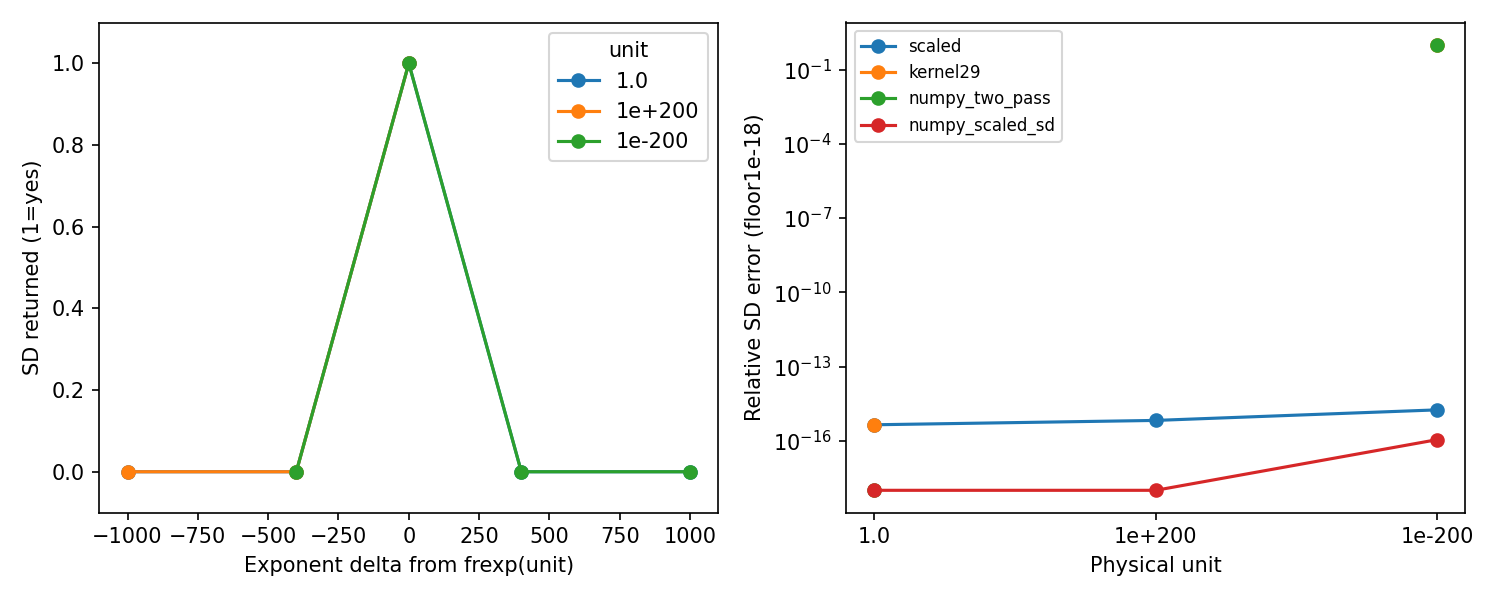

In [3]:
display(Image(filename='results/scale_audit.png'))

## 5 Ablación negativa y decisión
Sin escala: kernel29 y NumPy pueden devolver inf para varianza grande y cero para pequeña, aunque SD sea representable. No es fallo de NumPy devolver varianza no representable: el contrato de nuestra extensión distingue SD disponible y varianza no representable. Baseline fuerte NumPy dos pasadas sigue siendo mejor opción por rendimiento en dominio usual; no afirmamos speedup. Escala incorrecta se rechaza; no es detector universal de pérdida de significancia.
## 6 Enseñar los límites
En x=1e16+(0,1,2,3) se conserva el negativo29: ninguna escala recupera incrementos perdidos. Mezclas de órdenes1e±200 no caben juntas en nuestra ventana. Esto es limitación de diseño, no un teorema de imposibilidad para otros métodos. Prototipo acumulativo, sin validación operacional ni equivalencia S2=M2.

In [4]:
assert s['chosen_max_relative_sd_error']<=1e-12
assert scaled_moments([1e200,2e200],0).status=='normalization_failure'
print('Escala mala:',scaled_moments([1e200,2e200],0))
print('Rango mixto:',scaled_moments([1e-200,1e200],0))
print('Representación perdida:',scaled_moments([1e16+i for i in range(4)],54))

Escala mala: ScaleResult(n=0, exponent=0, status='normalization_failure', variance=None, std=None)
Rango mixto: ScaleResult(n=0, exponent=0, status='normalization_failure', variance=None, std=None)
Representación perdida: ScaleResult(n=4, exponent=54, status='ok', variance=2.75, std=1.6583123951777)
